# Model A: Prophet cloud-cost forecasting (CloudSense AI)
**Input (spec):** `ds`, `y` (+ optional regressors such as request count, active users, workload indicator). **Output:** 7 / 30 / 90-day forecast with 80% intervals, MAPE/RMSE/MAE, expected budget-overrun date.
**Spec parameters:** `growth=linear`, `daily_seasonality=False`, weekly seasonality when history supports it, `yearly_seasonality='auto'`, `interval_width=0.80`, horizons 7/30/90, rolling-origin validation, train on earlier dates only.

The training/inference logic lives in the importable package `cloudsense/forecasting.py` (so you can reuse it in your backend). This notebook runs it, shows EDA/evaluation, saves the model and lets you download it.
**Data source:** synthetic benchmark by default. For your real AWS account see the *Real data* cell (Cost Explorer / CUR collectors). The 5% MAPE target is a *goal*; the notebook reports what was measured.

In [1]:
import os, sys, json, warnings, logging, zipfile, time, platform
from pathlib import Path
warnings.filterwarnings("ignore"); logging.basicConfig(level=logging.INFO, format="%(levelname)s | %(message)s")
def _bootstrap():
    try: import cloudsense; return
    except ImportError: pass
    for c in [Path("."), Path(".."), Path("cloudsense_ml"), Path("/content/cloudsense_ml")]:
        if (c / "cloudsense").exists(): sys.path.insert(0, str(c.resolve())); return
    try:                                                         # Colab: upload cloudsense_ml.zip once
        from google.colab import files
        for n, b in files.upload().items(): open(n, "wb").write(b); zipfile.ZipFile(n).extractall(".")
        sys.path.insert(0, str(Path("cloudsense_ml").resolve()))
    except ImportError: raise ImportError("Put the cloudsense/ package folder next to this notebook (or in ../), or on Colab upload cloudsense_ml.zip")
_bootstrap()
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
import cloudsense; print("cloudsense", cloudsense.__version__)
def find_data(files):
    for c in ["data", "../data", "cloudsense_ml/data", "/content/data", "/content/cloudsense_ml/data"]:
        if all((Path(c) / f).exists() for f in files): return Path(c)
    try:
        from google.colab import files as cf; Path("data").mkdir(exist_ok=True)
        for n, b in cf.upload().items(): open(Path("data") / n, "wb").write(b)
        return Path("data")
    except ImportError: raise FileNotFoundError(f"Put {files} in ./data")
def make_outputs(tag):
    out = Path(f"outputs_{tag}"); fig = out / "figures"; art = out / "artifacts"
    for p in (fig, art): p.mkdir(parents=True, exist_ok=True)
    caps = {}
    def savefig(name, caption):
        plt.tight_layout(); plt.savefig(fig / f"{name}.png", dpi=105, bbox_inches="tight"); caps[name] = caption; plt.show()
    return out, fig, art, caps, savefig

from cloudsense import forecasting as fa
from cloudsense.common import jdump
OUT, FIG, ART, CAPS, savefig = make_outputs("model_a"); DATA = find_data(["A_cost_daily.csv"]); print("data:", DATA)

cloudsense 1.0.0


data: ../data


## 1. Load data (spec format: `ds`, `y`, optional regressors)

In [2]:
df = pd.read_csv(DATA / "A_cost_daily.csv", parse_dates=["ds"])
REGRESSORS = [c for c in ["api_requests", "active_users", "workload_index"] if c in df.columns]      # optional: any extra numeric columns
svc = pd.read_csv(DATA / "A_cost_by_service_daily.csv", parse_dates=["ds"]) if (DATA / "A_cost_by_service_daily.csv").exists() else None
cal = pd.read_csv(DATA / "A_calendar_events.csv", parse_dates=["ds"]) if (DATA / "A_calendar_events.csv").exists() else None   # optional marketing/holiday calendar (Prophet holidays format)
diag = pd.read_csv(DATA / "A_eval_only_diagnostics.csv", parse_dates=["ds"]) if (DATA / "A_eval_only_diagnostics.csv").exists() else None   # EVALUATION ONLY (never a model input)
print(df.shape, df.ds.min().date(), "->", df.ds.max().date(), "| regressors:", REGRESSORS); df.head()

(1000, 5) 2024-01-01 -> 2026-09-30 | regressors: ['api_requests', 'active_users', 'workload_index']


,ds,y,api_requests,active_users,workload_index
0,2024-01-01,217.4547,6807247,189079,0.0
1,2024-01-02,220.0155,6582275,181528,0.0
2,2024-01-03,225.9419,7063414,193439,0.0
3,2024-01-04,225.2947,7098685,198431,0.0
4,2024-01-05,224.0328,6857260,187320,0.0


In [3]:
# ---- REAL DATA (optional): replace the CSV above with your AWS account's daily cost. Needs read-only credentials; Cost Explorer calls cost ~$0.01 each.
# from cloudsense.collectors import get_session
# from cloudsense.collectors.pipeline import build_model_a_frame
# s = get_session(profile="cloudsense-readonly", region="ap-south-1")
# df = build_model_a_frame("2025-01-01", "2026-10-01", metric="NetUnblendedCost", session=s)   # keep ONE cost basis for the whole series
# REGRESSORS = []   # or join api_requests / active_users on ds via the `regressors=` argument
print("Using the synthetic benchmark. See the commented block for real AWS data.")

Using the synthetic benchmark. See the commented block for real AWS data.


## 2. Cleaning and data-quality report

In [4]:
D = fa.prepare_daily(df, REGRESSORS)
dq = dict(rows=len(df), calendar_days=len(D), missing_dates=D.attrs["missing_dates"], cost_basis=D.attrs["cost_basis"], nonpositive=int((D.y.dropna() <= 0).sum()), auto_outlier_days=int(fa.outlier_mask(D.y.interpolate()).sum()))
jdump(dq, OUT / "data_quality.json"); print(json.dumps(dq, indent=1)); print("-> missing billing days stay NaN (never zero); regressor gaps are interpolated and flagged")

{
 "rows": 1000,
 "calendar_days": 1004,
 "missing_dates": [
  "2024-03-09",
  "2025-01-17",
  "2025-08-30",
  "2026-02-02"
 ],
 "cost_basis": "net unblended cost, USD",
 "nonpositive": 0,
 "auto_outlier_days": 81
}
-> missing billing days stay NaN (never zero); regressor gaps are interpolated and flagged


## 3. EDA

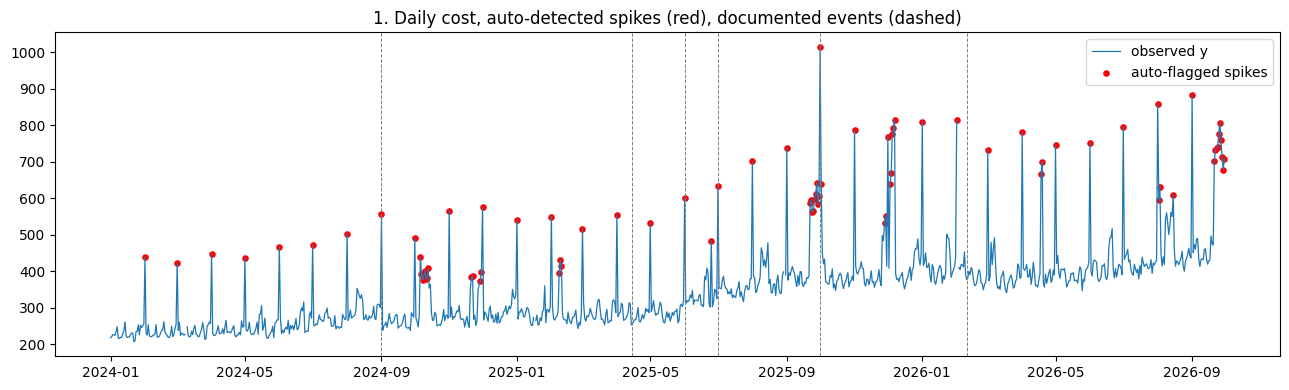

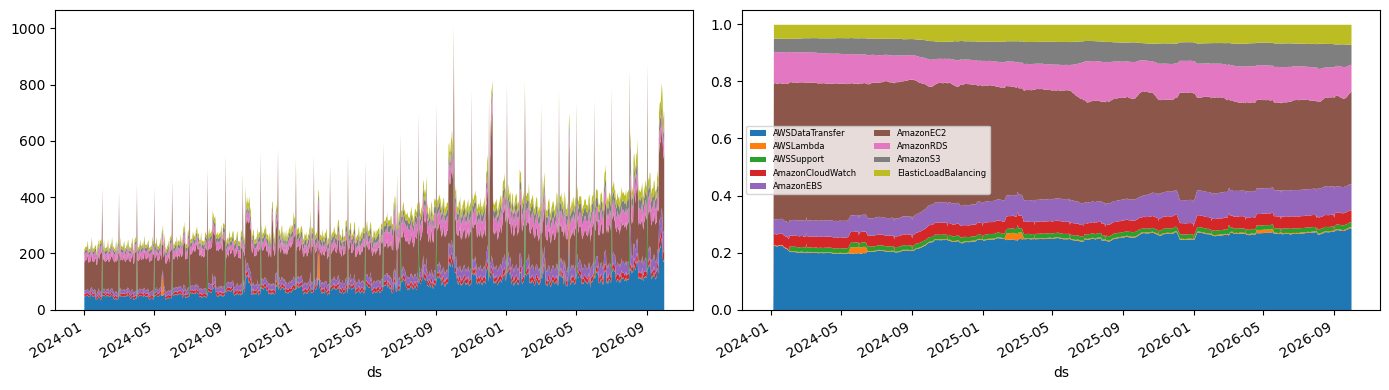

INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


INFO | Using categorical units to plot a list of strings that are all parsable as floats or dates. If these strings should be plotted as numbers, cast to the appropriate data type before plotting.


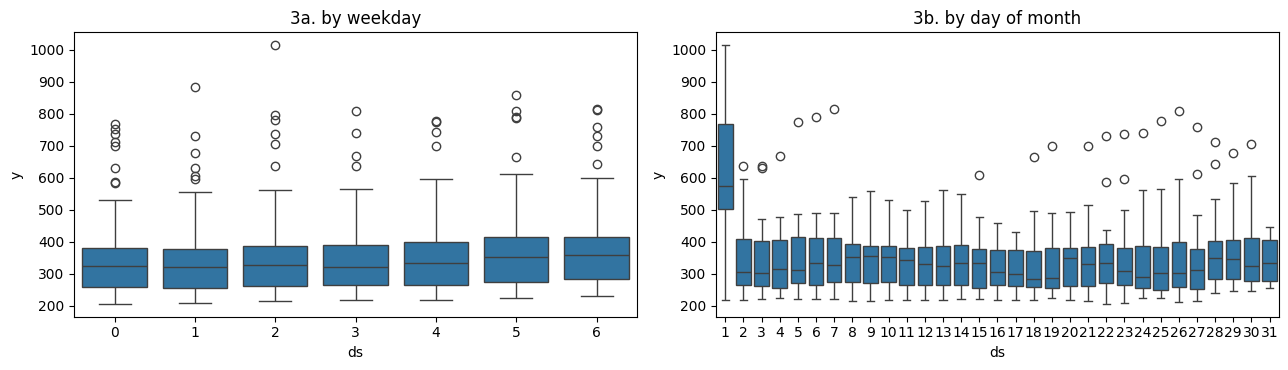

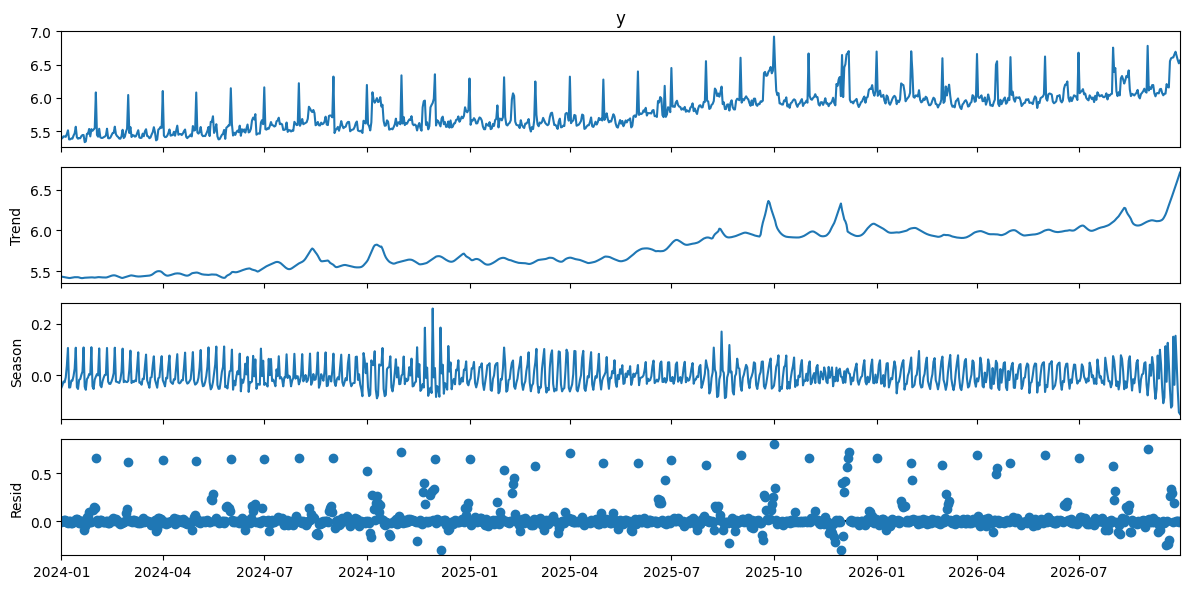

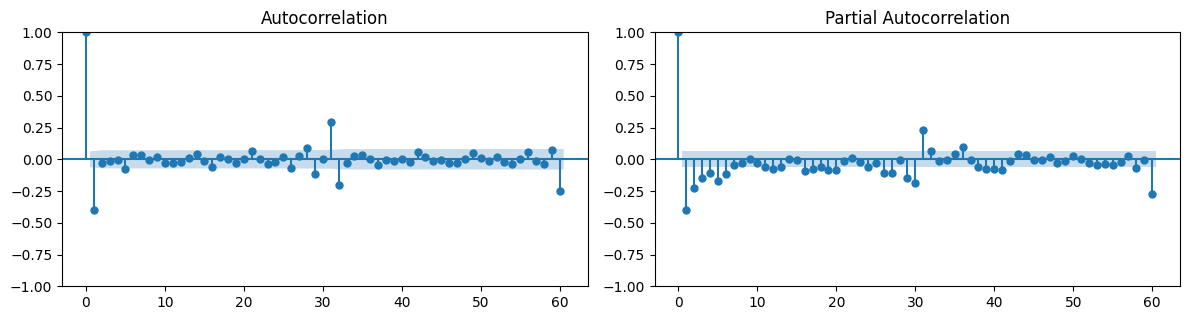

/tmp/ipykernel_515/3028783019.py:15: InterpolationWarning: The test statistic is outside of the range of p-values available in the look-up table. The actual p-value is smaller than the p-value returned.
  print(f"ADF p(level)={adfuller(ly)[1]:.3f} | ADF p(diff)={adfuller(d1)[1]:.4f} | KPSS p(level)={kpss(ly, nlags='auto')[1]:.3f}")


ADF p(level)=0.694 | ADF p(diff)=0.0000 | KPSS p(level)=0.010


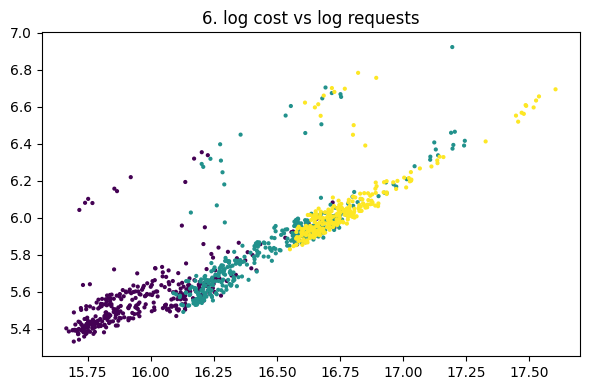

corr(cost, requests) by year: {2024: 0.593, 2025: 0.723, 2026: 0.667}


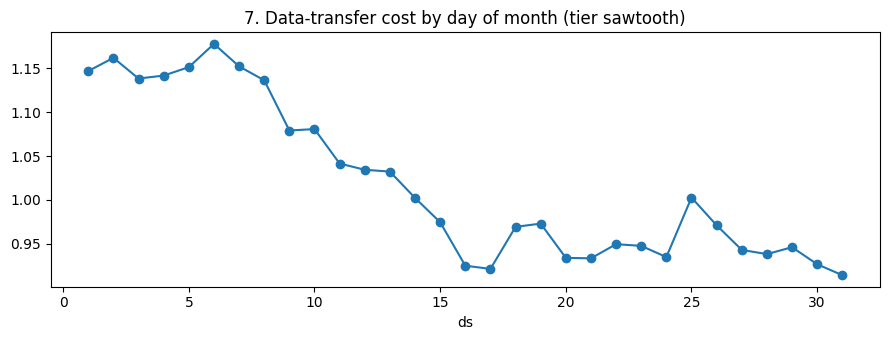

[diagnostics only] incident days 19, mean inflation vs y_clean 52.2%


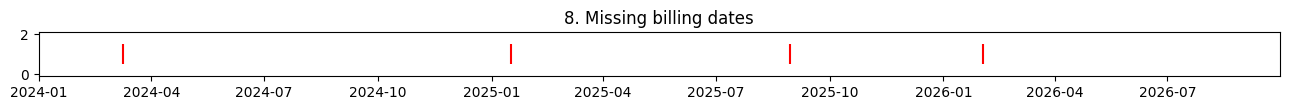

463

In [5]:
from statsmodels.tsa.seasonal import STL
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import adfuller, kpss
EVENTS = {"2024-09-01": "Savings Plan", "2025-04-15": "m5->m6g", "2025-06-01": "RDS resize", "2025-07-01": "App v3", "2025-10-01": "right-size", "2026-02-10": "Caching"}   # documented in the synthetic benchmark only
flag = fa.outlier_mask(D.y.interpolate())
fig, ax = plt.subplots(figsize=(13, 4)); ax.plot(D.index, D.y, lw=.9, label="observed y"); ax.scatter(D.index[flag], D.y[flag], c="red", s=14, label="auto-flagged spikes")
if diag is not None and "EVENTS" in globals():
    for d_, n_ in EVENTS.items(): ax.axvline(pd.Timestamp(d_), color="grey", ls="--", lw=.7)
ax.legend(); ax.set_title("1. Daily cost, auto-detected spikes (red), documented events (dashed)"); savefig("01_total_cost", "Total daily cost")
if svc is not None:
    W = svc.pivot_table(index="ds", columns="service", values="y"); fig, axs = plt.subplots(1, 2, figsize=(14, 4)); W.fillna(0).plot.area(ax=axs[0], lw=0, legend=False); W.div(W.sum(axis=1), axis=0).rolling(30, min_periods=5).mean().plot.area(ax=axs[1], lw=0); axs[1].legend(fontsize=6, ncol=2); savefig("02_services", "Cost by service and share")
fig, axs = plt.subplots(1, 2, figsize=(13, 3.8)); sns.boxplot(x=D.index.dayofweek, y=D.y, ax=axs[0]); axs[0].set_title("3a. by weekday"); sns.boxplot(x=D.index.day, y=D.y, ax=axs[1]); axs[1].set_title("3b. by day of month"); savefig("03_profiles", "Weekday / day-of-month profile")
stl = STL(np.log(D.y.interpolate()), period=7, robust=True).fit(); fig = stl.plot(); fig.set_size_inches(12, 6); savefig("04_stl", "STL decomposition")
ly = np.log(D.y.interpolate()); d1 = ly.diff().dropna(); fig, axs = plt.subplots(1, 2, figsize=(12, 3.3)); plot_acf(d1, lags=60, ax=axs[0]); plot_pacf(d1, lags=60, ax=axs[1]); savefig("05_acf_pacf", "ACF/PACF")
print(f"ADF p(level)={adfuller(ly)[1]:.3f} | ADF p(diff)={adfuller(d1)[1]:.4f} | KPSS p(level)={kpss(ly, nlags='auto')[1]:.3f}")
if "api_requests" in D:
    fig, ax = plt.subplots(figsize=(6, 4)); ax.scatter(np.log(D.api_requests), np.log(D.y), s=4, c=D.index.year); ax.set_title("6. log cost vs log requests"); savefig("06_cost_vs_requests", "Cost vs traffic"); print("corr(cost, requests) by year:", D.groupby(D.index.year).apply(lambda g: g.y.corr(g.api_requests)).round(3).to_dict())
if svc is not None and "AWSDataTransfer" in W:
    dt = W["AWSDataTransfer"]; fig, ax = plt.subplots(figsize=(9, 3.5)); (dt / dt.rolling(30, min_periods=10).mean()).groupby(dt.index.day).mean().plot(ax=ax, marker="o"); ax.set_title("7. Data-transfer cost by day of month (tier sawtooth)"); savefig("07_monthly_sawtooth", "Monthly pattern from tiered pricing")
if diag is not None:
    dd = diag.set_index("ds").join(D[["y"]]); inc = dd[dd.anomaly_type != "none"]; print(f"[diagnostics only] incident days {len(inc)}, mean inflation vs y_clean {(inc.y/inc.y_clean-1).mean():.1%}")
fig, ax = plt.subplots(figsize=(13, 1.2)); ax.eventplot([D.index[D.was_missing]], colors="red"); ax.set_xlim(D.index[0], D.index[-1]); ax.set_title("8. Missing billing dates"); savefig("08_missing", "Missing-date map")
open(OUT / "eda_summary.md", "w").write("""# EDA -> decisions
Trend + weekly seasonality + month pattern + level shifts -> flexible changepoints, monthly seasonality, tuned priors.
Spikes inflate the series -> automatic outlier masking in training (works without incident labels).
Cost follows traffic but future traffic is unknown -> oracle vs forecast-regressor variants (oracle never deployed).
Missing days stay NaN. Non-stationary level -> Prophet trend model; SARIMA baseline differences the series.
""")

## 4. Train: variants P0-P6 + baselines, rolling-origin CV, selection, ONE hold-out evaluation, production refit

In [6]:
t0 = time.time()
res = fa.train_forecaster(df, cal, regressors=REGRESSORS, service_df=svc, out_dir=ART / "model_registry" / "prophet_cost", progress=print)
print(f"done in {time.time()-t0:.0f}s | selected deployable: {res.best_variant} | best baseline: {res.baselines_best}")
cv = res.cv_summary.pivot(index="variant", columns="h", values="MAPE").round(2); cv["note"] = ["ORACLE regressors - not deployable" if "oracle" in i else "" for i in cv.index]; cv

ERROR | Importing plotly failed. Interactive plots will not work.


INFO | Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.


CV folds: [(540, 630), (630, 720), (720, 810), (810, 900)]


INFO | Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.


INFO | Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.


...

INFO | Disabling yearly seasonality. Run prophet with yearly_seasonality=True to override this.


P6_per_service done


selected deployable variant: P3_tuned


done in 86s | selected deployable: P3_tuned | best baseline: B_drift


h,7,30,90,note
variant,,,,
B_drift,13.60,11.30,11.23,
B_sarima,14.45,11.97,11.59,
B_snaive28,17.92,14.85,16.09,
B_snaive7,17.03,12.52,10.57,
P0_defaults,11.25,12.62,15.36,
P1_mask,12.38,10.64,11.13,
P2_mask_monthly,12.30,10.12,10.46,
P3_tuned,12.62,8.73,7.76,
P4_oracle_regs,8.37,7.74,7.90,ORACLE regressors - not deployable


## 5. Evaluation

HOLD-OUT (touched once; trained before the hold-out):
                                  MAPE     RMSE      MAE  coverage80    bias
h7                               2.590   14.968   10.534      71.429   4.949
h30                              4.770   75.504   26.425      63.333  -7.806
h90                              9.544  126.623   61.854      45.556 -52.956
snaive7_h7                      20.881  152.506   86.091         NaN  37.498
snaive7_h30                     18.441  165.439   82.828         NaN  31.624
snaive7_h90                     22.582  186.009  118.967         NaN -22.259
oracle_regs_h90_NOT_DEPLOYABLE   5.303   74.936   32.788         NaN -27.272

MAPE < 5% reached on hold-out? {7: True, 30: True, 90: False}


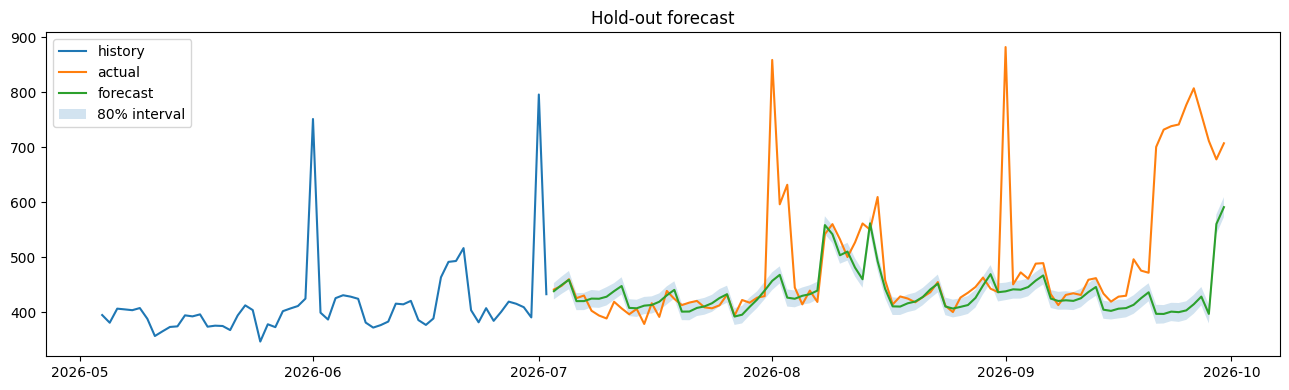

Diebold-Mariano vs seasonal-naive: stat=-44.94, p=0.0000 (Prophet better)


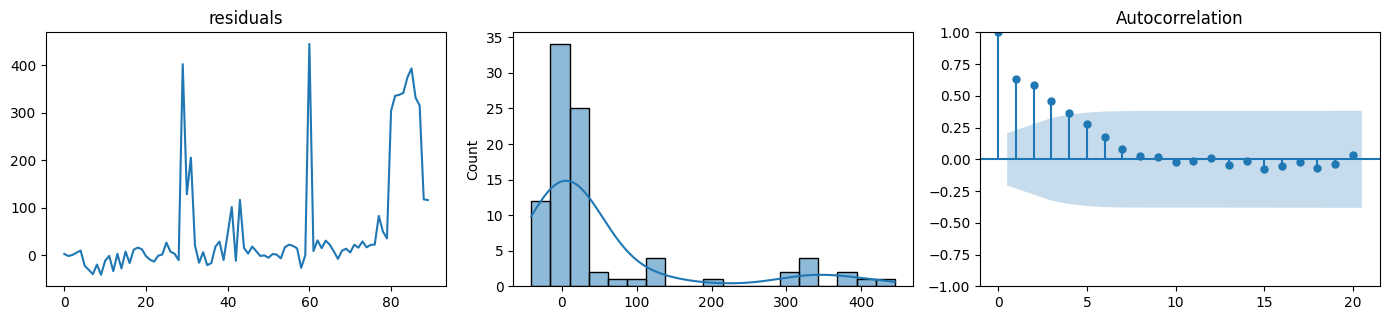

MAPE by incident/non-incident day (diagnostics): {False: 3.85, True: 38.01}


In [7]:
hr = pd.DataFrame(res.holdout).T.round(3); print("HOLD-OUT (touched once; trained before the hold-out):"); print(hr[[c for c in ["MAPE", "RMSE", "MAE", "coverage80", "bias"] if c in hr.columns]])
reached = {h: res.holdout[f"h{h}"]["MAPE"] < 5 for h in (7, 30, 90)}; print("\nMAPE < 5% reached on hold-out?", reached)
H = res.holdout_frame; fig, ax = plt.subplots(figsize=(13, 4)); ax.plot(D.index[-150:-len(H)], D.y[-150:-len(H)], label="history"); ax.plot(H.index, H.y, label="actual"); ax.plot(H.index, H.yhat, label="forecast"); ax.fill_between(H.index, H.yhat_lower, H.yhat_upper, alpha=.2, label="80% interval"); ax.legend(); ax.set_title("Hold-out forecast"); savefig("11_holdout_forecast", "Hold-out forecast vs actual")
from scipy import stats
ok = H.y.notna(); y_, p_ = H.y[ok].values, H.yhat[ok].values; sn = fa.baseline_predict("B_snaive7", D.iloc[:-len(H)], len(H))[ok.values]
d = np.abs(y_ - p_) - np.abs(y_ - sn); n = len(d); db = d.mean(); g = [np.mean((d[k:] - db) * (d[:n - k] - db)) for k in range(7)]; stat = db / np.sqrt(max((g[0] + 2 * sum(g[1:])) / n, 1e-12)); print(f"Diebold-Mariano vs seasonal-naive: stat={stat:.2f}, p={2*(1-stats.norm.cdf(abs(stat))):.4f} ({'Prophet better' if stat<0 else 'baseline better'})")
res_ = y_ - p_; fig, axs = plt.subplots(1, 3, figsize=(14, 3.3)); axs[0].plot(res_); axs[0].set_title("residuals"); sns.histplot(res_, kde=True, ax=axs[1]); plot_acf(res_, lags=20, ax=axs[2]); savefig("12_residuals", "Hold-out residuals")
print("MAPE by incident/non-incident day (diagnostics):", {k: round(v, 2) for k, v in (H.assign(e=(H.y - H.yhat).abs() / H.y * 100).groupby(flag.reindex(H.index).values).e.mean()).items()})

## 6. Use the saved model (inference class) and the budget-overrun date

  7-day forecast: total $3,121  (80% interval $3,008 - $3,235)
 30-day forecast: total $12,938  (80% interval $12,461 - $13,420)


 90-day forecast: total $39,056  (80% interval $37,576 - $40,527)


budget-overrun example: {'month': '2026-10', 'spent_to_date': 0.0, 'projected_month_total': 13405.44937946116, 'budget': 17717.964502, 'expected_overrun_date': None, 'earliest_overrun_date': None, 'latest_overrun_date': None}


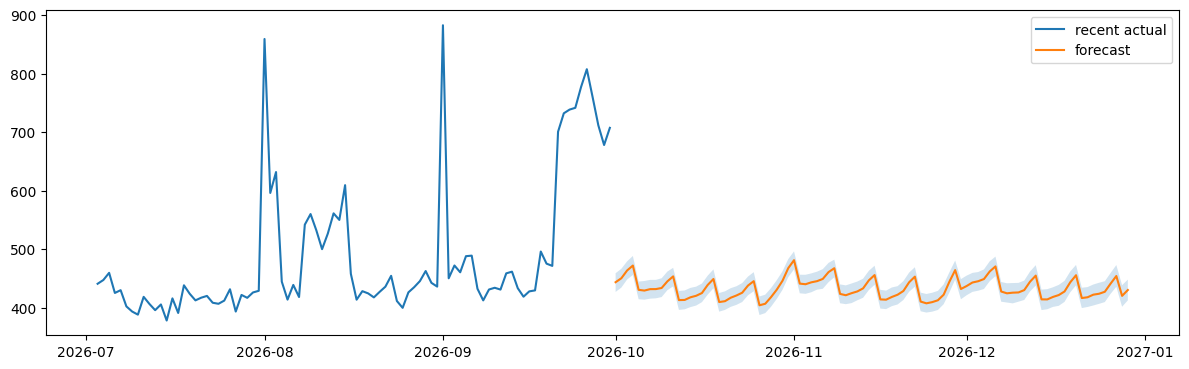

In [8]:
fc = fa.CostForecaster.load(res.bundle_dir)
for h in (7, 30, 90): f = fc.forecast(h); print(f"{h:>3}-day forecast: total ${f.yhat.sum():,.0f}  (80% interval ${f.yhat_lower.sum():,.0f} - ${f.yhat_upper.sum():,.0f})")
f90 = fc.forecast(90); f90.to_csv(ART / "forecast_next_90d.csv", index=False)
monthly_budget = float(D.y.iloc[-30:].mean() * 31 * 1.02)                     # example budget: slightly above the recent run-rate
print("budget-overrun example:", fc.budget_overrun(monthly_budget, D.index[-1]))
fig, ax = plt.subplots(figsize=(12, 3.8)); ax.plot(D.index[-90:], D.y[-90:], label="recent actual"); ax.plot(f90.ds, f90.yhat, label="forecast"); ax.fill_between(f90.ds, f90.yhat_lower, f90.yhat_upper, alpha=.2); ax.legend(); savefig("13_next_90d", "Forecast for the next 90 days")

In [9]:
# ------------------------------ TESTS ------------------------------
assert len(res.folds) >= 1 and all(b <= len(D) - 90 for _, b in res.folds), "CV fold reaches into the hold-out"
assert pd.Timestamp(res.meta["holdout_start"]) > D.index[-91], "hold-out must be the last 90 days"
assert not any(c in (res.meta["regressors"]) for c in ["y_clean", "anomaly_type", "anomaly_id"]), "diagnostic column used as regressor"
f1 = fc.forecast(30); assert list(f1.columns) == ["ds", "yhat", "yhat_lower", "yhat_upper"] and len(f1) == 30 and (f1.yhat_lower <= f1.yhat_upper).all() and f1.ds.is_monotonic_increasing
assert np.allclose(fc.forecast(30).yhat.values, f1.yhat.values), "inference must be deterministic"
try: fc.forecast(0); raise SystemExit("validation missing")
except ValueError: pass
print("all tests passed")

all tests passed


## 7. Report, zip and download

In [10]:
best = pd.DataFrame(res.holdout).T.loc[["h7", "h30", "h90"], ["MAPE", "RMSE", "MAE", "coverage80"]].round(3)
report = f"""# Model A results: Prophet cost forecasting
*Spec parameters: linear growth, no daily seasonality, weekly when supported, yearly=auto, 80% interval, horizons 7/30/90. Data: {df.ds.min().date()} to {df.ds.max().date()} ({len(df)} rows; synthetic benchmark unless you replaced it).*

## Validation design
Expanding-window rolling-origin CV ({len(res.folds)} folds), selection on mean MAPE at 30 days, final hold-out = last 90 days evaluated ONCE. Missing dates: {res.meta['missing_dates']} (kept as NaN).

## CV MAPE % by variant and horizon (P4 uses oracle future regressors: not deployable)
{cv.to_string()}

## Selected deployable model: {res.best_variant}  params: {res.best_params}
Hold-out (trained only before the hold-out):
{best.to_string()}
MAPE < 5% reached on this single hold-out window: {reached}
**Do not over-read this:** the hold-out is ONE 90-day window. Rolling-origin CV for the selected variant averages {cv.loc[res.best_variant, 30]:.1f}% MAPE at 30 days and {cv.loc[res.best_variant, 90]:.1f}% at 90 days over {len(res.folds)} folds. Report the CV figures as the expected accuracy and the hold-out as one confirmation.
Interval calibration: the nominal 80% intervals covered {best.loc["h7", "coverage80"]:.0f}% / {best.loc["h30", "coverage80"]:.0f}% / {best.loc["h90", "coverage80"]:.0f}% of actual days at 7/30/90 days, i.e. they are too narrow, especially for long horizons (cost incidents and level shifts are not in the uncertainty model).

## Limitations
Hold-out may contain incidents; regressors must be forecast (adds error); few CV folds; synthetic data unless replaced.
"""
open(OUT / "results_report.md", "w").write(report); json.dump(CAPS, open(FIG / "captions.json", "w"), indent=1); jdump(res.holdout, ART / "metrics.json"); res.cv_summary.to_csv(ART / "cv_summary.csv", index=False); res.tuning.to_csv(ART / "tuning_results.csv", index=False); print(report)
def zip_and_download(out: Path, name: str):
    zp = Path(name)
    with zipfile.ZipFile(zp, "w", zipfile.ZIP_DEFLATED) as z:
        for p in out.rglob("*"):
            if p.is_file(): z.write(p, p.relative_to(out.parent))
    print("zipped ->", zp.resolve(), f"({zp.stat().st_size/1e6:.1f} MB)")
    try:
        from google.colab import files; files.download(str(zp))              # Colab: browser download
    except ImportError: print("Not on Colab: the zip is in the working folder.")
zip_and_download(OUT, "model_A_prophet_artifacts.zip")

# Model A results: Prophet cost forecasting
*Spec parameters: linear growth, no daily seasonality, weekly when supported, yearly=auto, 80% interval, horizons 7/30/90. Data: 2024-01-01 to 2026-09-30 (1000 rows; synthetic benchmark unless you replaced it).*

## Validation design
Expanding-window rolling-origin CV (4 folds), selection on mean MAPE at 30 days, final hold-out = last 90 days evaluated ONCE. Missing dates: ['2024-03-09', '2025-01-17', '2025-08-30', '2026-02-02'] (kept as NaN).

## CV MAPE % by variant and horizon (P4 uses oracle future regressors: not deployable)
h                     7     30     90                                note
variant                                                                  
B_drift           13.60  11.30  11.23                                    
B_sarima          14.45  11.97  11.59                                    
B_snaive28        17.92  14.85  16.09                                    
B_snaive7         17.03  12.52  10.57             